# SPDC simulation with Matrix Product States

### Crank–Nicolson evolution, photon-number MPOs and state fidelity

We consider a quantum pump with $\alpha=5$ and a vacuum signal, and study the SPDC dynamics up to $T=1$ using a binary-encoded X-space MPS. The Hamiltonian is represented as an MPO and evolved with an implicit Crank–Nicolson solver.

An independent sparse Fock-basis calculation is carried out in `SPDC_in_photon_basis_reference.ipynb`. This notebook **only loads its saved results**. The two approaches are compared through mean photon numbers.

### Imports

In [6]:
import time
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm

import MatrixProductFunctions_torch as mp
import CN_torch as cn

torch.set_num_threads(1)
plt.rcParams['figure.figsize'] = (8, 5)

## 1. SPDC Hamiltonian in the X representation

For the pump ($a$) and signal ($b$) modes,

$$\hat H_{\mathrm{SPDC}}=i\hbar\chi\left(\hat a^\dagger\hat b^2-\hat a(\hat b^\dagger)^2\right).$$

With $\hbar=1$, $\hat a=(x_a+\partial_{x_a})/\sqrt2$ and $\hat b=(x_b+\partial_{x_b})/\sqrt2$, the **full interaction Hamiltonian** is

$$\boxed{\hat H_{\mathrm{SPDC}}=-\frac{i\chi}{\sqrt2}\left[\partial_{x_a}(x_b^2+\partial_{x_b}^2)-x_a\left(x_b\partial_{x_b}+\partial_{x_b}x_b\right)\right].}$$

In the continuum, $x_b\partial_{x_b}+\partial_{x_b}x_b=1+2x_b\partial_{x_b}$. On a **finite grid**, however, the symmetrized form is preferred: it keeps the discretized $\hat H$ Hermitian when the first-derivative matrix is anti-Hermitian. We work in the interaction picture and omit the free Hamiltonian.

## 2. Wavefunction in the X representation

Initially, the pump is coherent and the signal is in the vacuum:

$$|\Psi(0)\rangle=|\alpha\rangle_a\otimes|0\rangle_b,\qquad
\Psi(x_a,x_b,0)=\psi_\alpha(x_a)\psi_0(x_b).$$

For real $\alpha$,

$$\psi_\alpha(x_a)=\pi^{-1/4}\exp\!\left[-\frac{(x_a-\sqrt2\alpha)^2}{2}\right],\quad
\psi_0(x_b)=\pi^{-1/4}\exp(-x_b^2/2).$$

Each coordinate is sampled on $2^n$ points and represented using $n$ binary MPS tensors. Pump sites are followed by signal sites:

$$|\Psi\rangle=\sum_{s_1\dots s_{n_1+n_2}}A^{[1]s_1}A^{[2]s_2}\cdots A^{[n_1+n_2]s_{n_1+n_2}}|s_1\cdots s_{n_1+n_2}\rangle.$$

## 3. Choice of the computational grid

The pump is initially displaced by $x_{\rm bias}=\sqrt2\alpha$ while the signal starts in vacuum. 

In [7]:
chi = 0.5
alpha = 5.0                      # Real coherent-state amplitude

n1 = 8                           # Pump: 2**n1 grid points
n2 = 9                           # Signal: 2**n2 grid points

x_bias = alpha*np.sqrt(2)
x_left = 2*x_bias+6              # Physical pump interval: [-x_bias-6, x_bias+6]
x_right = 6
x_bond2 = 6                      # Signal interval: [-6, 6]

pump_mode_interval = np.linspace(x_bias-x_left, x_bias+x_right, 2**n1)
signal_mode_interval = np.linspace(-x_bond2, x_bond2, 2**n2)
step1 = pump_mode_interval[1]-pump_mode_interval[0]
step2 = signal_mode_interval[1]-signal_mode_interval[0]

t_general = 1
steps_number = 200
delta_t = t_general/steps_number

print('Pump grid:', 2**n1, 'points | dx =', round(step1, 6))
print('Pump interval:', (pump_mode_interval[0], pump_mode_interval[-1]))
print('Signal grid:', 2**n2, 'points | dx =', round(step2, 6))
print('Time steps:', steps_number, '| dt =', delta_t)

Pump grid: 256 points | dx = 0.102518
Pump interval: (np.float64(-13.071067811865476), np.float64(13.071067811865476))
Signal grid: 512 points | dx = 0.023483
Time steps: 200 | dt = 0.005


## 4. Hamiltonian as an MPO

We discretize **only the full physical Hamiltonian**

$$\boxed{\hat H_{\mathrm{SPDC}}=-\frac{i\chi}{\sqrt2}\left[\partial_{x_a}(x_b^2+\partial_{x_b}^2)-x_a(x_b\partial_{x_b}+\partial_{x_b}x_b)\right].}$$

A concatenation of two mode-local MPO lists represents their tensor product.

#### Pump-mode MPOs: $\partial_{x_a}$ and $-x_a$

In [8]:
coh_operator_one = mp.der_mpo(n1, step1)
coh_operator_two = mp.mpo_mul_num(mp.x_mpo(n1, x_bias-x_left, step1), -1)

#### Signal-mode MPOs: $x_b^2+\partial_{x_b}^2$ and $x_b\partial_{x_b}+\partial_{x_b}x_b$

In [9]:
x_signal = mp.x_mpo(n2, -x_bond2, step2)
der_signal = mp.der_mpo(n2, step2)

vac_operator_one = mp.mpo_sum(
    mp.x2_mpo(n2, -x_bond2, step2),
    mp.der2_mpo(n2, step2)
)
vac_operator_two = mp.mpo_sum(
    mp.mpo_multiplication(x_signal, der_signal),
    mp.mpo_multiplication(der_signal, x_signal)
)

#### Complete SPDC interaction Hamiltonian

In [10]:
first_part = coh_operator_one + vac_operator_one
second_part = coh_operator_two + vac_operator_two

full_hamiltonian = mp.mpo_mul_num(
    mp.mpo_sum(first_part, second_part), -1j*chi/np.sqrt(2)
)

print('Number of MPO tensors:', len(full_hamiltonian))
print('Maximum MPO bond:', max(max(t.shape[0], t.shape[-1]) for t in full_hamiltonian))

Number of MPO tensors: 17
Maximum MPO bond: 18


## 5. Initial wavefunction as an MPS

Initially the pump is coherent and the signal is in vacuum. The state is the tensor product of two Gaussian MPS wavefunctions. We normalize each discrete wavefunction so that the combined MPS norm is unity. The coherent displacement is incorporated through the **physical pump MPO coordinate**, while the stored pump Gaussian remains centered at zero.

Initial norm: 5.749293150571124
Initial bond: 10


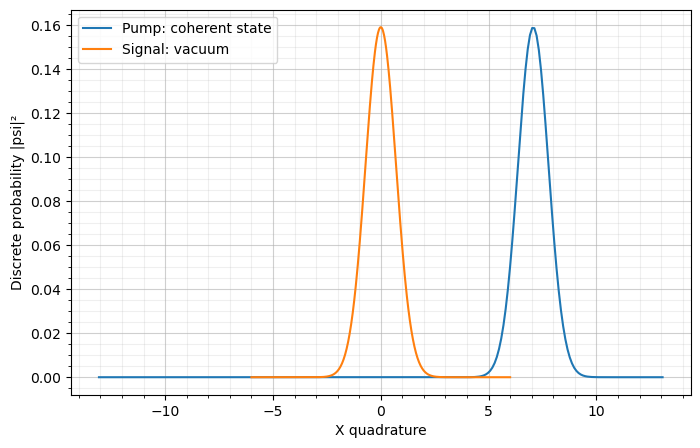

In [11]:
pump_initial_mps = mp.asym_gauss_mps(x_left, x_right, n1, 1, eps=1e-12)
signal_initial_mps = mp.asym_gauss_mps(x_bond2, x_bond2, n2, 1, eps=1e-12)

pump_initial_mps[0] = pump_initial_mps[0] #/cn.compute_norm(pump_initial_mps)
signal_initial_mps[0] = signal_initial_mps[0] #/cn.compute_norm(signal_initial_mps)
initial_state_mps = pump_initial_mps + signal_initial_mps

print('Initial norm:', cn.compute_norm(initial_state_mps).item())
print('Initial bond:', cn.get_bond(initial_state_mps))

plt.plot(pump_mode_interval, np.abs(mp.tensors_multiplication(pump_initial_mps).numpy())**2,
         label='Pump: coherent state')
plt.plot(signal_mode_interval, np.abs(mp.tensors_multiplication(signal_initial_mps).numpy())**2,
         label='Signal: vacuum')
plt.xlabel('X quadrature')
plt.ylabel('Discrete probability |psi|²')
plt.grid(which='major', alpha=0.6)
plt.grid(which='minor', alpha=0.2)
plt.minorticks_on()
plt.legend()
plt.show()

## 6. Crank–Nicolson time evolution and the initial guess

The Schrödinger equation $i\partial_t|\Psi(t)\rangle=\hat H_{\mathrm{SPDC}}|\Psi(t)\rangle$ is integrated as

$$\boxed{\left(I+\frac{i\Delta t}{2}\hat H_{\mathrm{SPDC}}\right)|\Psi_{k+1}\rangle
=\left(I-\frac{i\Delta t}{2}\hat H_{\mathrm{SPDC}}\right)|\Psi_k\rangle.}$$

To initialize each two-site sweep, the `evolution_op` setting constructs the **first-order time-evolution predictor**

$$\boxed{|\Psi_{k+1}^{(0)}\rangle\;\approx\;
\mathcal C_{\varepsilon_{\rm guess},\chi_{\rm guess}}\!\left[\left(I-i\Delta t\hat H_{\rm SPDC}\right)|\Psi_k\rangle\right],}$$

where $\mathcal C$ denotes MPS compression with its own truncation threshold and bond cap. The predictor is **not** the final CN update. The local CN linear systems are then solved iteratively through left-to-right and right-to-left sweeps.

## 7. Numerical parameters

In [12]:
initial_guess = ['evolution_op', 1e-4, 100, 2, 0.01, 1, 30]   # First-order predicted MPS, adaptive bond growth
eps = 1e-9                                                    # Local SVD truncation threshold
bond_limit = mp.get_bond(initial_state_mps)                   # Initial maximum MPS bond dimension
sweep_number = 1                                              # Left-right + right-left sweep cycles
renormalize = False                                           # Do not hide norm drift

right_part_eps = eps                                          # Compression of the CN right-hand-side MPS
right_part_bond_limit = bond_limit

print('Method: Crank-Nicolson')
print('Number of sweeps:', sweep_number, '| Initial maximum bond:', bond_limit)
print('Adaptive upper bound:', initial_guess[6])
print('Predictor maximum bond in the solver:', min(initial_guess[2], bond_limit))

Method: Crank-Nicolson
Number of sweeps: 1 | Initial maximum bond: 10
Adaptive upper bound: 30
Predictor maximum bond in the solver: 10


## 8. Accuracy control

We monitor the following diagnostics:

- **State norm:** a fully converged CN update with a Hermitian discrete Hamiltonian preserves $\langle\Psi|\Psi\rangle$. Here `renormalize=False` reveals numerical drift.
- **Global CN residual:** $\|A\Psi_{k+1}-b_k\|/\|b_k\|$ monitors the implicit solve.
- **Manley–Rowe invariant:** $2\langle N_a\rangle+\langle N_b\rangle=2|\alpha|^2$ for ideal degenerate SPDC.
- **Sparse Fock reference:** an independent calculation with the same $\alpha,\chi,T,\Delta t$.
- **Pure-state fidelity:** a direct overlap after projecting the X-space MPS onto sampled Fock wavefunctions represented as **MPS**. Finite X intervals and truncations are assessed independently.

## 9. MPS time evolution

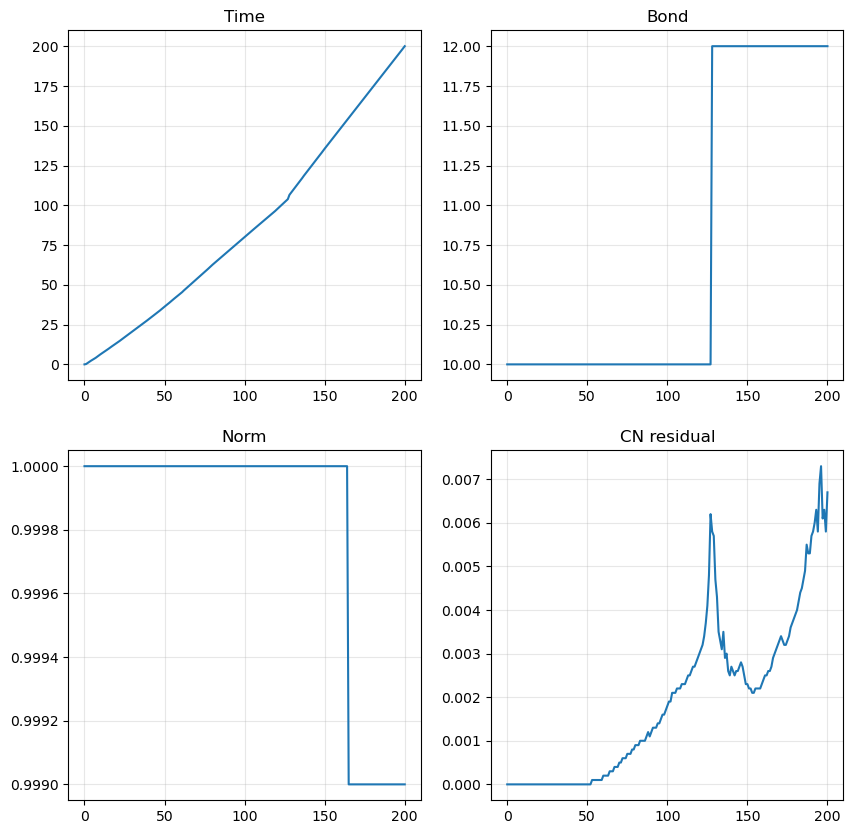

200 steps completed in 200.52 s
Final bond: 12


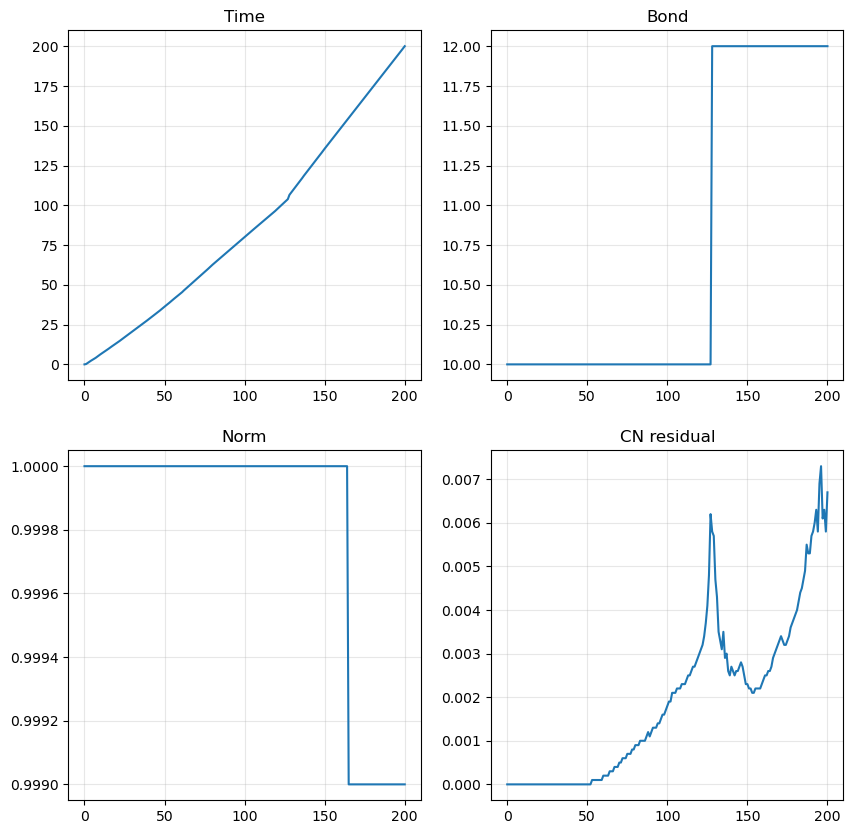

In [13]:
start_time = time.time()

set_of_solutions_cn = cn.CN_evolute(
    initial_state_mps, full_hamiltonian, steps_number, delta_t,
    cn.CN_solve, initial_guess=initial_guess, eps=eps,
    bond_limit=bond_limit, sweep_number=sweep_number,
    renormalize=renormalize, chart=True,
    right_part_eps=right_part_eps,
    right_part_bond_limit=right_part_bond_limit
)

mps_time = time.time()-start_time
times = np.arange(len(set_of_solutions_cn))*delta_t
print(f'{len(set_of_solutions_cn)-1} steps completed in {mps_time:.2f} s')
print('Final bond:', cn.get_bond(set_of_solutions_cn[-1]))

#### Monitoring the state norm, MPS bond dimension and sampled CN residual

100%|██████████| 20/20 [00:03<00:00,  5.54it/s]


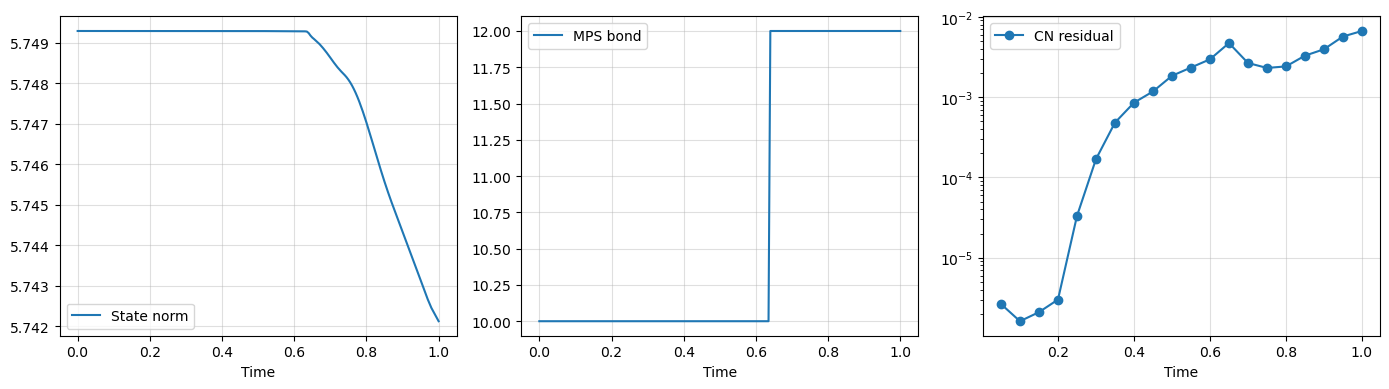

Maximum monitored CN residual: 0.00665850562827231
Maximum norm drift: 0.0071698687358887625


In [14]:
norms = np.array([cn.compute_norm(state).item() for state in set_of_solutions_cn])
bonds = np.array([cn.get_bond(state) for state in set_of_solutions_cn])

# Evaluate the global CN residual every ten steps (independent of sweep truncation).
residual_steps = np.arange(10, len(set_of_solutions_cn), 10)
residuals = []
evolution_operator_mpo = cn.make_cn_operators(full_hamiltonian, delta_t)
for i in tqdm(residual_steps):
    right_part = cn.compute_cn_right_part(
        full_hamiltonian, set_of_solutions_cn[i-1], delta_t,
        eps=right_part_eps, bond_limit=right_part_bond_limit
    )
    residuals.append(cn.compute_discrepancy(evolution_operator_mpo, set_of_solutions_cn[i], right_part))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(times, norms, label='State norm')
axes[1].plot(times, bonds, label='MPS bond')
axes[2].semilogy(times[residual_steps], residuals, 'o-', label='CN residual')
for ax in axes:
    ax.set_xlabel('Time')
    ax.grid(alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

print('Maximum monitored CN residual:', np.max(residuals))
print('Maximum norm drift:', np.max(np.abs(norms-norms[0])))

## 10. Photon-number dynamics from MPS–MPO–MPS contractions

For three modes, the number operators are embedded into the full Hilbert space as

$$\hat N_1=\hat n_1\otimes I_2,\qquad
\hat N_2=I_1\otimes\hat n_2.$$

The mean number in mode $j$ is given by

$$\boxed{\langle n_j\rangle=\frac{\langle\Psi|\hat N_j|\Psi\rangle}
{\langle\Psi|\Psi\rangle}.}$$

In the quadrature representation,

$$\hat n_j=\frac12\left(x_j^2-\partial_{x_j}^2-1\right).$$

The existing `mp.photon_number_operator_mpo` implements $(x^2-\partial_x^2)/2$, i.e. $\hat n+1/2$. Therefore **subtract $1/2$ after taking the normalized expectation value**. The operators are constructed once and reused.

100%|██████████| 21/21 [00:00<00:00, 127.60it/s]


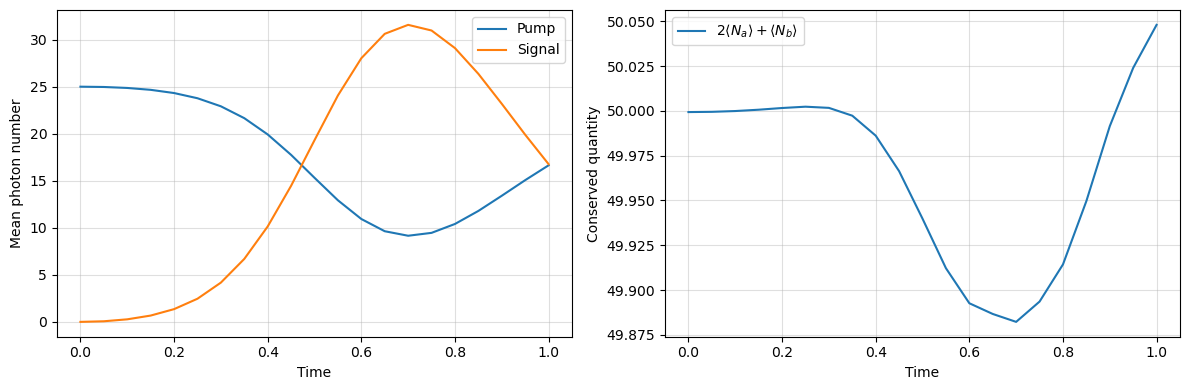

Initial photon numbers: 24.999671850684464 -1.7232598037708602e-05
Invariant drift: 0.0486950828217374


In [15]:
# Construct embedded photon-number MPOs.
def make_number_operators(n_modes, x0_modes, step_modes):
    number_ops = []

    for mode in range(len(n_modes)):
        number_mpo = []
        for j in range(len(n_modes)):
            if j == mode:
                number_mpo += mp.photon_number_operator_mpo(
                    n_modes[j], x0_modes[j], step_modes[j]
                )
            else:
                number_mpo += mp.one_mpo(n_modes[j])
        number_ops.append(number_mpo)

    return number_ops

number_ops = make_number_operators(
    [n1, n2], [x_bias-x_left, -x_bond2], [step1, step2]
)

pump_ph_stat = []
signal_ph_stat = []
for i in tqdm(range(0, len(set_of_solutions_cn), 10)):
    psi = set_of_solutions_cn[i]
    norm2 = mp.mps_scalar_multiplication(psi, psi).real

    pump_ph_stat.append(
        (mp.mps_mpo_mps(psi, number_ops[0]).real/norm2 - 0.5).item()
    )
    signal_ph_stat.append(
        (mp.mps_mpo_mps(psi, number_ops[1]).real/norm2 - 0.5).item()
    )

measurement_steps = np.arange(0, len(set_of_solutions_cn), 10)
measurement_times = measurement_steps*delta_t
pump_ph_stat = np.asarray(pump_ph_stat)
signal_ph_stat = np.asarray(signal_ph_stat)
invariant_mps = 2*pump_ph_stat + signal_ph_stat

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(measurement_times, pump_ph_stat, '-', label='Pump')
axes[0].plot(measurement_times, signal_ph_stat, '-', label='Signal')
axes[0].set_ylabel('Mean photon number')
axes[1].plot(measurement_times, invariant_mps, '-', label=r'$2\langle N_a\rangle+\langle N_b\rangle$')
axes[1].set_ylabel('Conserved quantity')
for ax in axes:
    ax.set_xlabel('Time')
    ax.grid(alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

print('Initial photon numbers:', pump_ph_stat[0], signal_ph_stat[0])
print('Invariant drift:', invariant_mps[-1]-invariant_mps[0])

## 11. Comparison with the saved sparse Fock calculation

The independent sparse Fock CN calculation uses $n_a=80$, $n_b=160$ and **200** steps up to $T=1$. It stores the observables and the state vectors at every tenth time step in `spdc_sparse_reference_cn_alpha5_T1.npz`. These reference data are **loaded here**, not generated by this notebook.

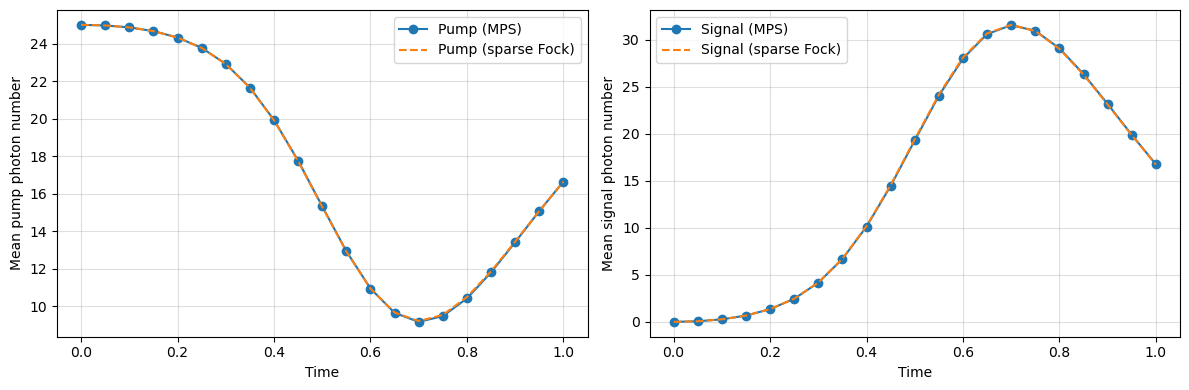

Maximum pump deviation: 0.07238905043865351
Maximum signal deviation: 0.1269560370532581
Sparse invariant drift: -2.842170943040401e-14


In [16]:
reference_path = Path('spdc_sparse_reference_cn_alpha5_T1.npz')
if not reference_path.is_file():
    raise FileNotFoundError(
        f'{reference_path} is missing. Run SPDC_in_photon_basis_reference_T1.ipynb first.'
    )

with np.load(reference_path) as sparse_data:
    reference_times = sparse_data['times']
    reference_pump = sparse_data['pump_photons']
    reference_signal = sparse_data['signal_photons']
    reference_norms = sparse_data['norms']
    reference_invariant = sparse_data['invariant']
    reference_alpha = float(sparse_data['alpha'])
    reference_chi = float(sparse_data['chi'])
    reference_steps = int(sparse_data['steps_number'])
    reference_dt = float(sparse_data['delta_t'])

assert np.isclose(reference_alpha, alpha), 'Reference alpha does not match the MPS calculation.'
assert np.isclose(reference_chi, chi), 'Reference chi does not match the MPS calculation.'
assert reference_steps == steps_number, 'Reference step count does not match.'
assert np.isclose(reference_dt, delta_t), 'Reference time step does not match.'
assert np.allclose(reference_times, times), 'Reference time grid does not match.'

pump_ph_stat_sparse = reference_pump[measurement_steps]
signal_ph_stat_sparse = reference_signal[measurement_steps]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(measurement_times, pump_ph_stat, 'o-', label='Pump (MPS)')
axes[0].plot(measurement_times, pump_ph_stat_sparse, '--', label='Pump (sparse Fock)')
axes[0].set_ylabel('Mean pump photon number')
axes[1].plot(measurement_times, signal_ph_stat, 'o-', label='Signal (MPS)')
axes[1].plot(measurement_times, signal_ph_stat_sparse, '--', label='Signal (sparse Fock)')
axes[1].set_ylabel('Mean signal photon number')
for ax in axes:
    ax.set_xlabel('Time')
    ax.grid(alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

print('Maximum pump deviation:', np.max(np.abs(pump_ph_stat-pump_ph_stat_sparse)))
print('Maximum signal deviation:', np.max(np.abs(signal_ph_stat-signal_ph_stat_sparse)))
print('Sparse invariant drift:', reference_invariant[-1]-reference_invariant[0])

## 12. Practical limitations of the MPS approach

**Initial guess.** For this long-range MPO, `initial_guess='best'` can fail to create enough long-range correlations during two-site sweeps. The first-order `evolution_op` predictor is essential in this example.

**Bond growth.** The MPS needs enough bond dimension to represent emerging entanglement. Increasing the number of grid points without increasing the bond dimension may produce an unstable calculation.

**Long-range couplings.** Binary encoding places interacting quadrature degrees of freedom on distant sites; this makes state expansion through local updates difficult.

**Dense local linear systems.** A two-site solve works with matrices whose dimensions grow roughly as the product of the left and right bonds, so modest increases in bond cap can substantially increase runtime and RAM.

## 13. Discussion of time-evolution strategies

**Sweep-based implicit tDMRG / CN.** The initial guess is freely selected, and additional sweeps can improve the local linear-system solution. At large bonds the dense local systems are expensive, and iterative methods need reliable preconditioning.

**Two-site TDVP (TDVP2).** Two-site projected evolution can efficiently update the MPS and grow its bond, but long-range couplings in the binary representation can be difficult to capture with limited local updates. It does not offer the same freely chosen next-state predictor as an implicit linear solver.

**Global subspace expansion with one-site TDVP (GSE-TDVP).** Expanding the global variational subspace can improve the representation of long-range couplings while maintaining fast one-site evolution. The enlarged space is not necessarily exploited optimally.